# Unstructured Data Analytics HW1

Name: Kelly McManus

Andrew ID: kellymcm

Collaborators (if none, say "none"; do *not* leave this blank): Cole Thomas

Reminder: you should not be sharing code.

**Warning: make sure your compute environment is set up first.** This homework assignment assumes that you have already installed Anaconda Python 3 and spaCy. Instructions for installing these are part of the tutorial [here](https://www.andrew.cmu.edu/user/georgech/95-865/Anaconda,%20Jupyter,%20and%20spaCy%20setup%20tutorial.pdf).

### Instructions
1. Fill in your name, Andrew ID, and collaborators above.
2. Fill in the code/text blocks to answer each question.
3. Do *not* change any of the existing code provided.
4. Run the entire notebook *before* submitting it on Canvas to make sure that the code actually runs without errors. (**Important**: Any code cells that you have entered code for but did not actually execute will be disregarded, so please be sure to actually run your code first and make sure it runs without errors! We may re-run a subset of your code for grading purposes.)
5. Be careful about where you save data for use with this Jupyter notebook (more details on this later).

### [Problem 1] Basic Text Analysis [45 pts]

This problem involves a mix of Python review (loops, conditionals, counters/dictionaries, sorting) and learning to work with a sizable collection of text data.

You will be looking at a phenomenon of "natural languages" (i.e., human languages, such as English) called *Zipf's law*, which relates how frequently a word occurs in a language to its "rank" (the word with rank 1 is the most frequently occurring word, the word with rank 2 is the second most frequently occurring word, etc). Roughly speaking, the word with rank 1 appears twice as likely as the word with rank 2, and the three times as likely as the word with rank 3, and so forth. (Some details on Zipf's law can be found on [Wikipedia](https://en.wikipedia.org/wiki/Zipf%27s_law).) In this problem, you are going to check whether Zipf's law holds for a real dataset of text documents.

The dataset we look at is a collection of the 100 most popular books downloaded from the [Gutenburg Project](https://www.gutenberg.org/browse/scores/top). These 100 books form the corpus that we consider for this problem. Each file contains the text of a book. We will read in all 100 books.

Note: Please *do not* change the folder name or the path, and make sure you use a relative path (e.g. './HW1_Dataset/*filename*) when reading the files. When grading your homework, we will put your Jupyter notebook file and the dataset in the same folder, and run your code. **You will not receive points for this problem if your code fails to load the data.**

Hint: To list all files that match a certain pattern, you can use the `glob` package. Here's an example usage:

```python
import glob
print(glob.glob('./HW1_Dataset/*.txt'))
```

**(a) Warm-up/basic Python review [15 pts across subparts].** This part serves as a warm-up, getting you familiar with the kind of code we will be writing in this class. Note that throughout part (a), your code should **not** be using spaCy.

**Subpart i [5 pts].** Write a loop that iterates through all 100 books; for each book, print out its corresponding file name and also how long the book is in terms of string length (meaning that if we load in the book as a string, we compute the length of the string using the built-in Python function `len`; this is just counting the number of characters).

**Please do not actually print out the contents of each book since many of the books are extremely long, and by printing out all the books' contents, you'll end up creating a Jupyter notebook that has a massive file size.**

Hint: When debugging your code, you may want to first make sure your code runs on a few of the books rather than all 100 (for example, you can start by only having 3 of the text files in `HW1_Dataset`). Once you're confident that your solution is correct on a few text files, then run on all of them! This is a standard approach to debugging code that is meant to handle large datasets.

Your output should look like (although there should be 100 books rather than 3 as shown below; also, the ordering of the books might be different on your machine):

```
./HW1_Dataset/War and Peace by graf Leo Tolstoy (251).txt 3227580
./HW1_Dataset/Democracy in America — Volume 1 by Alexis de Tocqueville (147).txt 1148435
./HW1_Dataset/Frankenstein; Or, The Modern Prometheus by Mary Wollstonecraft Shelley (501).txt 441034
```

In [2]:
import glob

In [3]:
fileFolder = './HW1_Dataset/*.txt'

# Extracts txt file into string and returns  
def readText(filename):
    text = ""
    for line in open(filename, encoding="utf8"):
        text += line
    return text

# Loops through each file in file folder and print filename and length
for file in list(glob.glob(fileFolder)):
    fileText = readText(file)
    print(file, len(fileText))

./HW1_Dataset\A Christmas Carol in Prose; Being a Ghost Story of Christmas by Charles Dickens (265).txt 177758
./HW1_Dataset\A History of Spanish Literature by James Fitzmaurice-Kelly (109).txt 765918
./HW1_Dataset\A Modest Proposal by Jonathan Swift (233).txt 38966
./HW1_Dataset\A Study in Scarlet by Arthur Conan Doyle (163).txt 262340
./HW1_Dataset\A Tale of Two Cities by Charles Dickens (425).txt 776702
./HW1_Dataset\Adventures of Huckleberry Finn by Mark Twain (401).txt 593962
./HW1_Dataset\Alice in Wonderland by Lewis Carroll and Alice Gerstenberg (126).txt 104079
./HW1_Dataset\Alice's Adventures in Wonderland by Lewis Carroll (564).txt 163817
./HW1_Dataset\Anne of Green Gables by L. M.  Montgomery (114).txt 580635
./HW1_Dataset\Autobiography of Benjamin Franklin by Benjamin Franklin (247).txt 458600
./HW1_Dataset\Beowulf An Anglo-Saxon Epic Poem (403).txt 292953
./HW1_Dataset\Beyond Good and Evil by Friedrich Wilhelm Nietzsche (120).txt 402273
./HW1_Dataset\Candide by Voltaire (1

**Subpart ii [5 pts].** Copy and paste your code from **subpart i** into the code cell below. Then in the code cell below, modify the code so that it prints out the top 15 longest books (in terms of raw string length, which is what you had already computed). In particular, please write your code so that the printout is of the following format:

```
1. <number of characters in longest text file> <filename of longest text file>
2. <number of characters in 2nd longest text file> <filename of 2nd longest text file>
...
15. <number of characters in 15th longest text file> <filename of 15th longest text file>
```

Note: only print out information for the top 15 books in the format above; please do not repeat printing what we asked you to print in **subpart i**.

In [6]:
from operator import itemgetter

books = []

# Loop through each file in file folder and append filename and length to books list
for file in list(glob.glob(fileFolder)):
    fileText = readText(file)
    fileLength = len(fileText)
    books.append([file, fileLength])

# Sort books
sorted_books = sorted(books, reverse=True, key=itemgetter(1))

# Print top 15 books by length
top = 15
for idx, book in enumerate(sorted_books[:top], 1):
    print('{}. {} {}'.format(idx, book[1], book[0]), end='\n')
    i += 1

1. 5465100 ./HW1_Dataset\The Complete Works of William Shakespeare by William Shakespeare (132).txt
2. 4351846 ./HW1_Dataset\The King James Version of the Bible (132).txt
3. 3254333 ./HW1_Dataset\Les Mise╠ürables by Victor Hugo (165) (Unicode Encoding Conflict).txt
4. 3227580 ./HW1_Dataset\War and Peace by graf Leo Tolstoy (251).txt
5. 3033575 ./HW1_Dataset\Essays of Michel de Montaigne ΓÇö Complete by Michel de Montaigne (205).txt
6. 2643849 ./HW1_Dataset\The Count of Monte Cristo, Illustrated by Alexandre Dumas (160).txt
7. 1534140 ./HW1_Dataset\Ulysses by James Joyce (282).txt
8. 1378627 ./HW1_Dataset\My Secret Life, Volumes I. to III. by Anonymous (157).txt
9. 1238569 ./HW1_Dataset\Moby Dick; Or, The Whale by Herman Melville (413).txt
10. 1231784 ./HW1_Dataset\Leviathan by Thomas Hobbes (417).txt
11. 1214387 ./HW1_Dataset\The Republic by Plato (246).txt
12. 1200021 ./HW1_Dataset\The History of the Peloponnesian War by Thucydides (122).txt
13. 1175588 ./HW1_Dataset\The Iliad by Home

**Subpart iii [5 pts].** You should find that some of the books are quite long. Processing very long books will be problematic with spaCy, so we will want to chop up long books into pieces. Note that later on in the course, we shall see that chopping up large amounts of data into small pieces or "batches" is in fact quite common in machine learning since for massive datasets, we often cannot store them in their entirety on a CPU or GPU for processing all at once.

As a toy example, suppose that a book's text is `'cat dog shark spam eggs'` and we want to split it up into batches where each batch has at most 3 words. Then we could split up the book's text into two batches/pieces: `'cat dog shark'` and `'spam eggs'`.

We have provided code for you to do this below.

In [7]:
import numpy as np

def split_into_batches(book_text, max_num_words_per_batch):
    words_split_on_spaces = book_text.split(' ')
    num_book_pieces = int(np.ceil(len(words_split_on_spaces) / max_num_words_per_batch))
    batches = []
    for piece_idx in range(num_book_pieces):
        start_idx = piece_idx * max_num_words_per_batch
        end_idx = (piece_idx + 1) * max_num_words_per_batch
        if end_idx > len(words_split_on_spaces):
            end_idx = len(words_split_on_spaces)
        book_piece = ' '.join(words_split_on_spaces[start_idx:end_idx])
        batches.append(book_piece)
    return batches

print(split_into_batches('cat dog shark spam eggs', 3))

['cat dog shark', 'spam eggs']


Now write a loop that goes through all 100 books again. However, for each book, split it up into batches so that each batch has at most 10000 words. In this case, how many batches are there total across all 100 books? Please write code that computes this number of batches. Your code should print out the following (with the correct total number of batches):

```
Total number of batches: <total number of batches across all 100 books>
```

In [9]:
allBatches = []
maxWords = 10000

# Convert all file texts to small batches of text
for file in list(glob.glob(fileFolder)):
    fileText = readText(file)
    batches = split_into_batches(fileText, maxWords)
    allBatches += batches

print('Total number of batches: {}'.format(len(allBatches)))

Total number of batches: 1246


**(b) [10 pts]** Now we will finally use spaCy. Note that for this problem, you don't actually need `spaCy`'s named entity recognition or grammatical parsing. Turning these elements off when you instantiate the `nlp` object can substantially speed up your code. To make sure these are off when instantiating the `nlp` object, call: 

```python
nlp = spacy.load('en_core_web_sm', disable=['ner', 'parser'])
```

**Throughout this problem, do not remove stopwords.**

Build a term frequency (raw counts) table that is for all 100 books. Specifically, building on your solution to part (a)-subpart iii, read in a single book at a time and for each book, do the following:

  1. Split it up into batches where each batch has at most 10000 words.
  2. For each batch:
    1. Process the batch by separating and lemmatizing the words
    2. Count the number of times each lemma appears and add these to the frequency table. For simplicity, **do not convert lemmas to lowercase**. (Note that we use raw counts as the "frequency"--do not do any division.) Also, as we explain below, we will only count lemmas that are alphanumeric.

Note that just as we had said in part (a): do **not** print out the complete contents of every book since doing so will result in a Jupyter notebook file that is massive.

After looping through all 100 books, you should have the term frequency table for the entire corpus (importantly, the frequency table should not just be for a single book; it should be for all 100 books). Sort the table and print the top 50 most frequent words, along with their frequencies and ranks. Don't worry about ties (for example, if multiple things have the same frequency, it's fine if your solution breaks ties arbitrarily in the sorting).

Note: When counting the lemmas, only include lemmas that consist of alphabetic letters (a-z and A-Z). You can do this with what's called a *regular expression*. For example, to check whether the words "will.i.am" or "Tesla" are alphabetic, you would do the following:

```python
import re  # regular expression package
if re.match('[a-zA-Z]+$', 'will.i.am'):
    print('will.i.am consists only of alphabetic letters!')
if re.match('[a-zA-Z]+$', 'Tesla'):
    print('tesla consists only of alphabetic letters!')
```

In [11]:
import spacy
import re
from collections import Counter

nlp = spacy.load('en_core_web_sm', disable=['ner', 'parser'])

In [12]:
lemma_frequency = Counter()
lemmas = []

# Loop through each file and create batches
for file in list(glob.glob(fileFolder)):
    fileText = readText(file)
    batches = split_into_batches(fileText, maxWords)
    
    # Loop through each batch in file
    for batch in batches: 
        
        # Loop through each token in batch, extract lemma 
        for token in nlp(batch):
            if re.match('[a-zA-Z]+$', token.orth_):
                lemmas.append(token.lemma_)

# Add lemma to frequency dictionary or increment lemma count
for lemma in lemmas:
    lemma_frequency[lemma] += 1

top = 50
sorted_lemma_frequency = lemma_frequency.most_common()

# Print top 50 words and frequency
for idx, value in enumerate(sorted_lemma_frequency[:top], 1):
    print('{}. {} {}'.format(idx, value[0], value[1]), end='\n')

ValueError: not enough values to unpack (expected 3, got 2)

**(c) [10 pts]** Visualize the frequency table by plotting a **raw scatter plot** (put frequency as the y-axis and rank as the x-axis), and a **log-log plot** (use logarithmic scales on both the x- and y- axes). Note that this should be for all words and not only the top 50. As before, for the ranks, do not worry about ties, i.e., break ties arbitrarily.

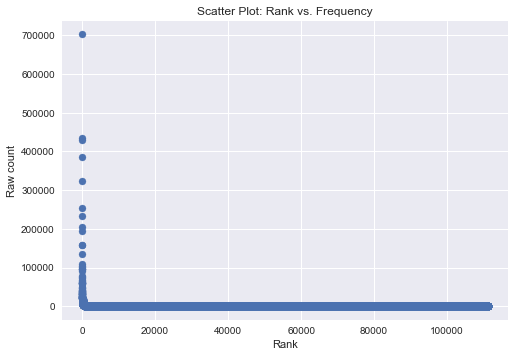

In [51]:
import matplotlib.pyplot as plt
plt.style.use('seaborn') 

top = len(sorted_lemma_frequency) # All lemmas
top_lemmas = [lemma for lemma, count in sorted_lemma_frequency[:top]]
top_counts = [count for lemma, count in sorted_lemma_frequency[:top]]

# Scatter plot
plt.scatter(range(top), top_counts)
plt.title('Scatter Plot: Rank vs. Frequency')
plt.xlabel('Rank')
plt.ylabel('Raw count')
plt.show()

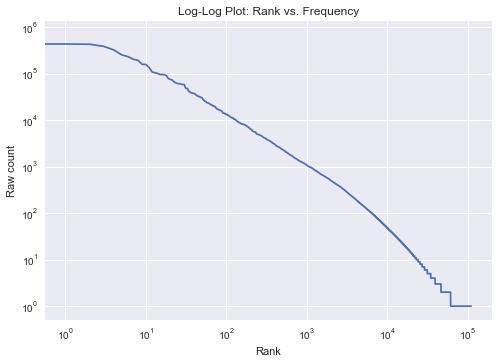

In [52]:
# Log-log plot
plt.loglog(range(top), top_counts) # DOUBLE CHECK
plt.title('Log-Log Plot: Rank vs. Frequency')
plt.xlabel('Rank')
plt.ylabel('Raw count')
plt.show()

**(d) [10 pts across subparts]** Let's now try to make sense of the very last plot in part **(c)**. Zipf's law states that term frequency is governed by a power law, i.e. the relationship between term frequency and rank can be approximated by $f(r) = cr^{-1}$, where $f(r)$ is the frequency of the term at rank $r$, $r$ is the rank of a term, and $c$ is a constant that is approximately 0.1*(corpus size) for English.

Please answer the following questions:

**Subpart i [3 pts].** What do you observe in the log-log plot above? Is this consist with the power law?

Your text answer (for this question, your answer is *not* code): *** The log-log plot is observed to be consistent with the power of law. As the rank increases, the frequency is negatively decreasing overall. At the start, the log-log slowly curves downward. In the middle, it is almost linear. At the end, it becomes stepwise. These all align with the shape of Zipf's law for log(rank) vs. log(frequency). *** 

**Subpart ii [4 pts].** Think of the corpus as a (large) unigram bag of words. Following the analogy from lecture, imagine drawing a single word from this big bag (note that we are assuming that we've lemmatized the words and also filtered out non-alphanumeric words; thus what remains in the bag are actually alphanumeric lemmas). What is the probability of drawing one of the 4 most frequent alphanumeric lemmas? What is the probability of drawing one of the 50 most frequent alphanumeric lemmas? Answer these two questions using code rather than just entering in the final answers as numbers.

In [70]:
# Initialize word counters
totalWords = 0
count4FreqWords = 0
count50FreqWords = 0

# Count words
[totalWords := totalWords + row[1] for row in sorted_lemma_frequency]
[count4FreqWords := count4FreqWords + row[1] for row in sorted_lemma_frequency[:4]]
[count50FreqWords := count50FreqWords + row[1] for row in sorted_lemma_frequency[:50]]

print('Probability of drawing one of the 4 most frequent alphanumeric lemmas: ')
print('{:.2%}'.format(count4FreqWords/totalWords))

print('Probability of drawing one of the 50 most frequent alphanumeric lemmas: ')
print('{:.2%}'.format(count50FreqWords/totalWords))

Probability of drawing one of the 4 most frequent alphanumeric lemmas: 
16.21%
Probability of drawing one of the 50 most frequent alphanumeric lemmas: 
48.20%


**Subpart iii [4 pts].** What proportion of the alphanumeric lemmas occur only once? What proportion of the alphanumeric lemmas occur fewer than 10 times?

In [74]:
# Initilize word counter
countOnceFreqWords = 0
countFewer10FreqWords = 0

# Count words
[countOnceFreqWords := countOnceFreqWords + row[1] 
    for row in sorted_lemma_frequency
    if row[1] == 1]
[countFewer10FreqWords := countFewer10FreqWords + row[1] 
    for row in sorted_lemma_frequency
    if row[1] <= 10]


print("Occur only once: ")
print('{:.2%}'.format(countOnceFreqWords/totalWords))

print("Occur fewer than 10 times: ")
print('{:.2%}'.format(countFewer10FreqWords/totalWords))

Occur only once: 
0.41%
Occur fewer than 10 times: 
1.67%


### [Problem 2] Entity Recognition and Pointwise Mutual Information (PMI) [50 pts]
By using the entity recognition system in `spaCy`, let's identify named entities from newspaper articles. You'll be using Reuters corpus which contains more than ten thousand newspaper articles. To run the code below, you need to download the Reuters dataset. To do so, in a terminal/command line (recall that you can open a terminal from Jupyter's webpage that shows all the files, which by default is [http://localhost:8888/tree](http://localhost:8888/tree)), start up Python and enter:

```python
import nltk
nltk.download('reuters')
```

Then proceed to the problem subparts below.

Note that in this problem you will need named entity recognition but not grammatical parsing. Hence, you will want to instantiate the nlp object by calling:

```python
nlp = spacy.load('en_core_web_sm', disable=['parser'])
```


**(a) [15 pts]** Draw a bar chart in which one of the axes shows entity labels and the other shows the frequency of the corresponding label. Use the variables `reuters_nlp` and `label_counter` provided in the code below.

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import reuters
import re
import spacy
nlp = spacy.load('en_core_web_sm', disable=['parser', 'tagger'])
reuters_fileids = reuters.fileids()  # hint: when first debugging, consider looking at just the first few
reuters_nlp = [nlp(re.sub('\s+',' ', reuters.raw(i)).strip()) for i in reuters_fileids]
label_counter = Counter()

########################################################################
######################### Write your code here #########################
########################################################################

**(b) [15 pts]** Now list the top 10 most frequently occurring entities (entity text and the number of occurence) with label `ORG` (organization). Separately list the top 10 most frequently occurring entities with label `GPE` (geopolitical entity such as countries, cities, states) respectively. **In both cases, please convert the entity names to lowercase first before computing the top 10.**

Here, when counting the (raw count) frequency, we need to count how many articles have an entity with the desired property. For every article, we add 1 if the article has the entity and 0 otherwise.

In [ ]:
########################################################################
######################### Write your code here #########################
########################################################################

**(c) [20 pts]** Give the top 50 `GPE` (countries, cities, states) entities that have the highest Pointwise Mutual Information (PMI) values with regard to the `ORG` (organization) entity **'opec'** (your list of this top 50 should be ranked in decreasing PMI value). Did you find any unexpected results? If so, why do you think it happened? If you found some of the results to be unsurprisingly, how come? **Just like in the previous part, please convert entity names to lowercase in your analysis.**

Hint 1: As in lecture, when computing PMI, we will compute probabilities by counting the number of documents where entities occur or co-occur.  For example, $P('opec') = \frac{number \ \ of \ \ documents \ \ containing \ \ 'opec'}{number \ \ of \ \ documents}$.  

Hint 2: To compute this ranking, you do not have to compute the full PMI equation.

In [ ]:
########################################################################
######################### Write your code here #########################
########################################################################

Your text answer (for this question, your answer is *not* code): *** WRITE YOUR ANSWER HERE ***

### [Problem 3] Questionnaire [5 pts]

Please provide feedback! To receive the 5 points, be sure to enter your Andrew ID correctly in this Google form: https://forms.gle/6CfMBvBxy5aYpJDN6